<a href="https://colab.research.google.com/github/carrotst1ck/ML-SU-3-Course/blob/main/pr9_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


In [2]:

X, y = make_moons(
    n_samples=400,
    noise=0.25,
    random_state=42
)

print("Размер датасета:", X.shape)
print("Количество классов:", len(np.unique(y)))


Размер датасета: (400, 2)
Количество классов: 2


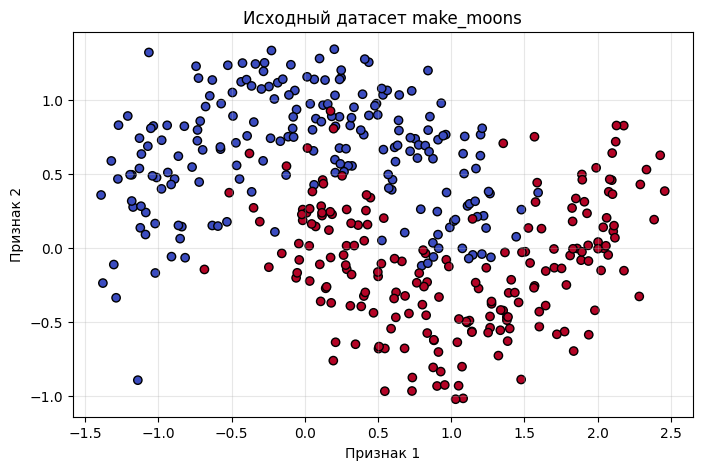

In [3]:

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Исходный датасет make_moons")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.grid(alpha=0.3)
plt.show()


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (320, 2)
Тестовая выборка: (80, 2)


In [5]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Средние значения признаков:")
print(scaler.mean_)

print("\nМасштабированные данные:")
print(X_train_scaled[:5])


Средние значения признаков:
[0.52737581 0.26139698]

Масштабированные данные:
[[ 1.54333189 -0.63104621]
 [-0.00465851 -0.66272875]
 [-1.6470492   0.84277614]
 [-1.76829025 -0.30767076]
 [-0.63879611  1.21728837]]


In [6]:

svm_linear = SVC(
    kernel="linear",
    C=1
)

svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)

print("Линейное ядро")
print("Accuracy:", accuracy_score(y_test, y_pred_linear))
print("Количество опорных векторов:", len(svm_linear.support_vectors_))


Линейное ядро
Accuracy: 0.9375
Количество опорных векторов: 129


In [7]:

svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)

print("RBF-ядро")
print("Accuracy:", accuracy_score(y_test, y_pred_rbf))
print("Количество опорных векторов:", len(svm_rbf.support_vectors_))


RBF-ядро
Accuracy: 0.925
Количество опорных векторов: 100


In [8]:

def plot_decision_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid)
    predictions = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 5))

    plt.contourf(
        xx, yy, predictions,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black"
    )

    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Опорные векторы"
    )

    plt.title(title)
    plt.xlabel("Признак 1")
    plt.ylabel("Признак 2")
    plt.legend()
    plt.show()


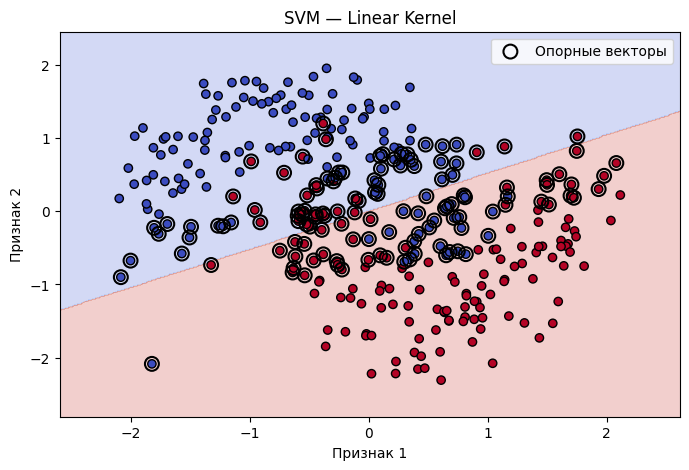

In [9]:

plot_decision_boundary(
    svm_linear,
    X_train_scaled,
    y_train,
    "SVM — Linear Kernel"
)


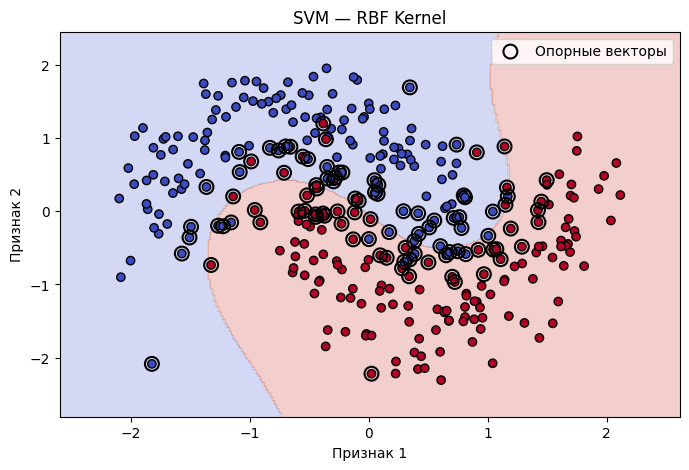

In [10]:

plot_decision_boundary(
    svm_rbf,
    X_train_scaled,
    y_train,
    "SVM — RBF Kernel"
)


In [11]:

C_values = [0.1, 1, 100]

svm_models = {}

for c in C_values:

    model = SVC(
        kernel="rbf",
        C=c,
        gamma="scale"
    )

    model.fit(X_train_scaled, y_train)

    svm_models[c] = model

    predictions = model.predict(X_test_scaled)

    print("C =", c)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Опорные векторы:", len(model.support_vectors_))
    print("-" * 30)


C = 0.1
Accuracy: 0.9625
Опорные векторы: 176
------------------------------
C = 1
Accuracy: 0.925
Опорные векторы: 100
------------------------------
C = 100
Accuracy: 0.9
Опорные векторы: 51
------------------------------


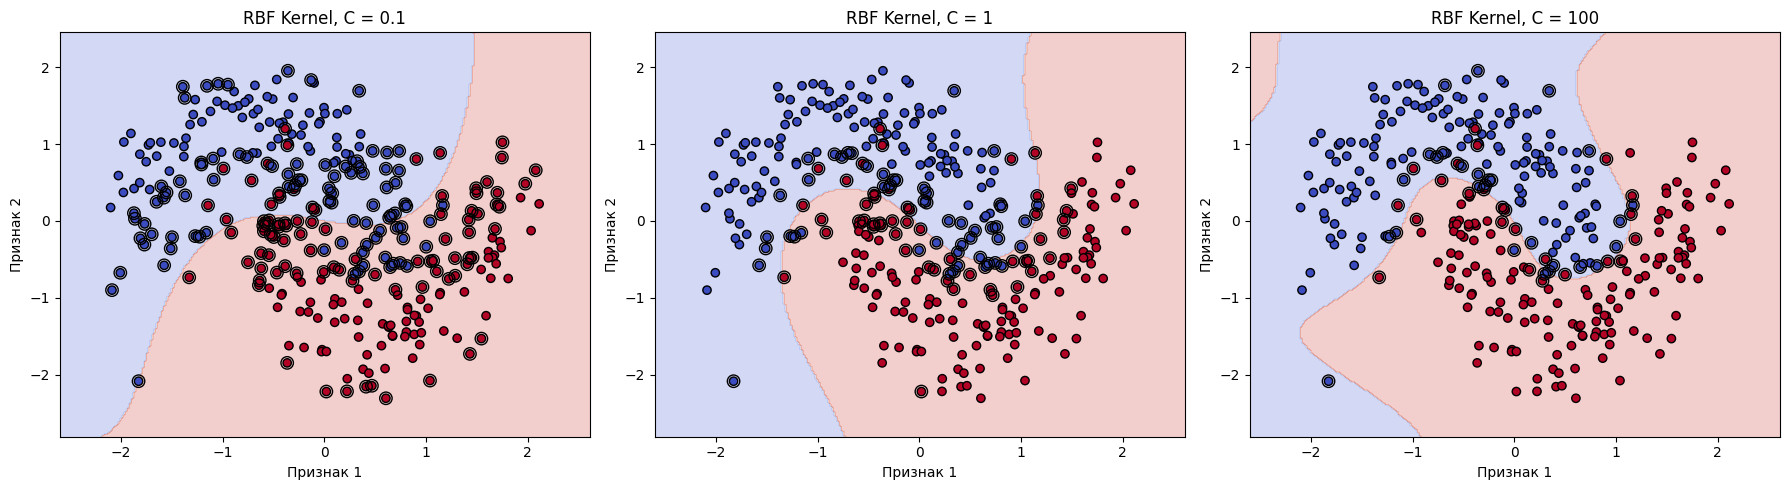

In [12]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c in zip(axes, C_values):

    model = svm_models[c]

    x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
    y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        alpha=0.25,
        cmap="coolwarm"
    )

    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black"
    )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=80,
        facecolors="none",
        edgecolors="black"
    )

    ax.set_title(f"RBF Kernel, C = {c}")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

plt.tight_layout()
plt.show()


In [13]:

from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Linear": svm_linear,
    "RBF": svm_rbf
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test_scaled)

    results.append([
        name,
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions),
        recall_score(y_test, predictions),
        f1_score(y_test, predictions)
    ])

import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

print(results_df.round(3))


    Model  Accuracy  Precision  Recall     F1
0  Linear     0.938      0.927   0.950  0.938
1     RBF     0.925      0.886   0.975  0.929


In [14]:

from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Linear": svm_linear,
    "RBF": svm_rbf
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test_scaled)

    results.append([
        name,
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions),
        recall_score(y_test, predictions),
        f1_score(y_test, predictions)
    ])

import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

print(results_df.round(3))


    Model  Accuracy  Precision  Recall     F1
0  Linear     0.938      0.927   0.950  0.938
1     RBF     0.925      0.886   0.975  0.929


In [15]:

for c, model in svm_models.items():

    predictions = model.predict(X_test_scaled)

    print(f"C = {c}")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("F1-score:", round(f1_score(y_test, predictions), 3))
    print()


C = 0.1
Accuracy: 0.963
F1-score: 0.964

C = 1
Accuracy: 0.925
F1-score: 0.929

C = 100
Accuracy: 0.9
F1-score: 0.9

